# Prueba A/B de landing pages: ¿conviene lanzar la versión B?

**Autor:** Mario Zarza Zárraga

Este análisis empezó como un proyecto del bootcamp de Data Analytics y lo amplié por mi cuenta con análisis de potencia, intervalos bootstrap, lift por segmento con corrección por comparaciones múltiples, controles de calidad del experimento (SRM) y una estimación del impacto en ingresos.

**Pregunta de negocio:** se mostraron dos versiones de una landing page (A = actual, B = nueva) a 40,000 usuarios durante 28 días. ¿B genera más compras y más ingreso que A, con suficiente evidencia como para lanzarla al 100% del tráfico?

**Métricas**

| Métrica | Definición | Prueba |
|---|---|---|
| Tasa de conversión | compradores / visitantes | z de dos proporciones y chi-cuadrada |
| Ticket promedio | gasto promedio de quienes compraron | t de Welch (+ Mann-Whitney como robustez) |
| ARPU | gasto promedio por visitante (incluye ceros) | t de Welch |

Nivel de significancia: α = 0.05, pruebas bilaterales. Los montos se reportan en \$ (el dataset no especifica la moneda).

**Contenido**

1. Carga de datos y controles de calidad (nulos, duplicados, SRM, balance de segmentos)
2. Conversión: prueba z, chi-cuadrada e intervalos de confianza
3. Ticket promedio y ARPU
4. Estabilidad en el tiempo
5. Intervalos bootstrap del lift
6. Análisis de potencia y efecto mínimo detectable
7. Análisis por segmento (Holm/Bonferroni y paradoja de Simpson)
8. Impacto de negocio por cada 10,000 visitantes
9. Recomendación y limitaciones

In [1]:
# Librerías (solo matplotlib para gráficas, sin seaborn)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep, proportion_confint
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.contingency_tables import StratifiedTable

pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.linestyle': ':', 'grid.alpha': 0.6})
COLORES = {'A': '#94a3b8', 'B': '#2563eb'}
ALPHA = 0.05
SEED = 42
rng = np.random.default_rng(SEED)

# Rutas relativas: funciona si se ejecuta desde la raíz del repo o desde notebook/
RAIZ = Path('.') if Path('data/landing_experiment.csv').exists() else Path('..')
DATA = RAIZ / 'data/landing_experiment.csv'
IMG = RAIZ / 'images'
IMG.mkdir(exist_ok=True)

def guardar(fig, nombre):
    fig.savefig(IMG / nombre, dpi=150, bbox_inches='tight')

## 1. Carga de datos y controles de calidad

Antes de comparar resultados hay que confirmar que el experimento se puede analizar: datos completos, un registro por usuario y una asignación a A/B que realmente haya sido aleatoria.

In [2]:
df = pd.read_csv(DATA)
print(f"Filas: {len(df):,} | Columnas: {df.shape[1]}")
df.head()

Filas: 40,000 | Columnas: 9


,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.0800
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.0000
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.0000
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.0000
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.0000


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  str    
 1   date            40000 non-null  str    
 2   landing         40000 non-null  str    
 3   region          40000 non-null  str    
 4   dispositivo     40000 non-null  str    
 5   traffic_source  40000 non-null  str    
 6   user_type       40000 non-null  str    
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), str(7)
memory usage: 2.7 MB


Columnas: `user_id`, `date` (día de exposición), `landing` (A/B), `region`, `dispositivo`, `traffic_source`, `user_type` (Nuevo/Recurrente), `converted` (0/1) y `gasto` (0 si no compró).

In [4]:
# --- Nulos y duplicados ---
print("Nulos por columna:")
print(df.isna().sum().to_string())
print(f"\nFilas duplicadas completas: {df.duplicated().sum()}")
print(f"user_id duplicados: {df['user_id'].duplicated().sum()}")
print(f"Usuarios en más de una landing: {(df.groupby('user_id')['landing'].nunique() > 1).sum()}")

# --- Categorías ---
for col in ['landing', 'region', 'dispositivo', 'traffic_source', 'user_type', 'converted']:
    print(f"\n{col}: {df[col].value_counts().to_dict()}")

# --- Consistencia entre converted y gasto ---
print(f"\nGastos negativos: {(df['gasto'] < 0).sum()}")
print(f"converted=1 con gasto=0: {((df['converted'] == 1) & (df['gasto'] == 0)).sum()}")
print(f"converted=0 con gasto>0: {((df['converted'] == 0) & (df['gasto'] > 0)).sum()}")

# --- Fechas ---
df['date'] = pd.to_datetime(df['date'])
print(f"\nPeriodo: {df['date'].min().date()} a {df['date'].max().date()} "
      f"({df['date'].nunique()} días con datos)")

cat_cols = ['landing', 'region', 'dispositivo', 'traffic_source', 'user_type']
df[cat_cols] = df[cat_cols].astype('category')

Nulos por columna:
user_id           0
date              0
landing           0
region            0
dispositivo       0
traffic_source    0
user_type         0
converted         0
gasto             0

Filas duplicadas completas: 0
user_id duplicados: 0
Usuarios en más de una landing: 0

landing: {'B': 20018, 'A': 19982}

region: {'Norte': 11166, 'Centro': 9613, 'Sur': 8039, 'Occidente': 6398, 'Oriente': 4784}

dispositivo: {'Mobile': 24829, 'Desktop': 15171}

traffic_source: {'Organic': 17987, 'Ads': 11935, 'Email': 6123, 'Referral': 3955}

user_type: {'Nuevo': 26033, 'Recurrente': 13967}

converted: {0: 34294, 1: 5706}

Gastos negativos: 0
converted=1 con gasto=0: 0
converted=0 con gasto>0: 0

Periodo: 2026-01-01 a 2026-01-28 (28 días con datos)


**Hallazgos de calidad**

- No hay valores nulos ni filas duplicadas. Cada `user_id` aparece una sola vez y ningún usuario vio ambas versiones, así que los grupos son independientes.
- Las categorías no tienen valores inesperados y `converted` solo toma 0 y 1.
- `gasto` es exactamente 0 cuando `converted = 0` y positivo cuando `converted = 1`; no hay gastos negativos.
- El experimento cubre del 1 al 28 de enero de 2026 (28 días, 4 semanas completas).

### 1.1 Sample Ratio Mismatch (SRM) y balance de segmentos

Si el reparto A/B se aleja mucho del 50/50 planeado, suele indicar un error de asignación o de registro, y en ese caso los resultados no son confiables. Se usa una chi-cuadrada de bondad de ajuste con el umbral habitual de p < 0.001. También se revisa que la mezcla de canales, tipos de usuario, dispositivos y regiones sea igual en A y B.

In [5]:
# Sample Ratio Mismatch: ¿la división observada es compatible con un 50/50?
n_obs = df['landing'].value_counts().sort_index()
esperado = np.array([len(df) / 2, len(df) / 2])
chi2_srm, p_srm = stats.chisquare(n_obs.values, f_exp=esperado)
print("Usuarios por landing:", n_obs.to_dict())
print(f"Proporción en B: {n_obs['B'] / n_obs.sum():.4%}")
print(f"SRM chi-cuadrada = {chi2_srm:.4f}, p = {p_srm:.4f}")
print("Alerta SRM (p < 0.001)" if p_srm < 0.001 else "Sin evidencia de SRM (p >= 0.001)")

# Balance de covariables: ¿la mezcla de segmentos es igual en A y B?
print("\nBalance de segmentos entre A y B (chi-cuadrada de independencia):")
filas = []
for col in ['traffic_source', 'user_type', 'dispositivo', 'region']:
    tabla = pd.crosstab(df[col], df['landing'])
    chi2, p, dof, _ = stats.chi2_contingency(tabla)
    filas.append({'variable': col, 'chi2': chi2, 'gl': dof, 'p_valor': p})
balance = pd.DataFrame(filas)
balance

Usuarios por landing: {'A': 19982, 'B': 20018}
Proporción en B: 50.0450%
SRM chi-cuadrada = 0.0324, p = 0.8572
Sin evidencia de SRM (p >= 0.001)

Balance de segmentos entre A y B (chi-cuadrada de independencia):


,variable,chi2,gl,p_valor
0,traffic_source,3.5693,3,0.3119
1,user_type,0.0664,1,0.7966
2,dispositivo,0.0219,1,0.8825
3,region,7.9047,4,0.0951


In [6]:
# SRM día por día (para detectar fallas puntuales en la asignación)
diario = pd.crosstab(df['date'], df['landing'])
diario['p_srm'] = diario.apply(lambda r: stats.chisquare([r['A'], r['B']]).pvalue, axis=1)
print(f"Días con p_srm < 0.01: {(diario['p_srm'] < 0.01).sum()} de {len(diario)}")
print(f"Usuarios por día: mín {diario[['A','B']].sum(axis=1).min():,}, máx {diario[['A','B']].sum(axis=1).max():,}")

Días con p_srm < 0.01: 0 de 28
Usuarios por día: mín 1,363, máx 1,512


**Resultado:** no hay evidencia de SRM. B recibió 50.05% del tráfico (p = 0.857) y ningún día muestra un desbalance (p < 0.01). La mezcla de segmentos tampoco difiere entre A y B (todas las p > 0.05; la más baja es región, p = 0.095). La asignación se comporta como aleatoria, así que las diferencias entre A y B se pueden atribuir a la landing.

## 2. Tasa de conversión

**Hipótesis**

- H₀: la tasa de conversión de B es igual a la de A.
- H₁: las tasas son diferentes.
- α = 0.05

In [7]:
# Tasa de conversión por landing
conv = df.groupby('landing', observed=True)['converted'].agg(usuarios='count', compradores='sum', tasa='mean')
nA, nB = conv.loc['A', 'usuarios'], conv.loc['B', 'usuarios']
xA, xB = conv.loc['A', 'compradores'], conv.loc['B', 'compradores']
pA, pB = xA / nA, xB / nB

# IC al 95% de cada tasa (Wilson)
conv['ic_inf'], conv['ic_sup'] = proportion_confint(conv['compradores'], conv['usuarios'], method='wilson')

# Prueba z de dos proporciones (bilateral)
z_conv, p_conv = proportions_ztest([xB, xA], [nB, nA])
# Chi-cuadrada sobre la tabla 2x2 (equivalente, sin corrección de Yates)
tabla_conv = pd.crosstab(df['landing'], df['converted'])
chi2_conv, p_chi2_conv, _, _ = stats.chi2_contingency(tabla_conv, correction=False)
# IC al 95% de la diferencia B - A (Newcombe)
ic_diff_conv = confint_proportions_2indep(xB, nB, xA, nA, method='newcomb', compare='diff')

print(conv)
print(f"\nDiferencia B - A: {(pB - pA) * 100:.2f} pp | lift relativo: {(pB / pA - 1):.2%}")
print(f"IC 95% de la diferencia: [{ic_diff_conv[0] * 100:.2f}, {ic_diff_conv[1] * 100:.2f}] pp")
print(f"Prueba z: z = {z_conv:.3f}, p = {p_conv:.3e}")
print(f"Chi-cuadrada: chi2 = {chi2_conv:.3f}, p = {p_chi2_conv:.3e}")

         usuarios  compradores   tasa  ic_inf  ic_sup
landing                                              
A           19982         2512 0.1257  0.1212  0.1304
B           20018         3194 0.1596  0.1545  0.1647

Diferencia B - A: 3.38 pp | lift relativo: 26.92%
IC 95% de la diferencia: [2.70, 4.07] pp
Prueba z: z = 9.677, p = 3.763e-22
Chi-cuadrada: chi2 = 93.651, p = 3.763e-22


**Resultado:** B convierte 15.96% frente a 12.57% de A, es decir, +3.38 puntos porcentuales (lift relativo de +26.9%). El IC al 95% de la diferencia va de 2.70 a 4.07 pp, y la prueba z da p = 3.8 × 10⁻²² (la chi-cuadrada sin corrección es equivalente y da el mismo valor p). **Se rechaza H₀.**

## 3. Ticket promedio (solo compradores) y ARPU

### 3.1 Forma de la distribución

El ticket se compara **solo entre quienes compraron**. Antes de elegir la prueba se revisa la forma de la distribución.

       count    mean     std     min     25%     50%     75%      max  \
A 2,512.0000 61.0866 28.8755 12.1200 40.6125 55.8400 74.8375 303.6800   
B 3,194.0000 68.7454 32.0010 12.9800 45.2100 62.5700 84.2775 249.9900   

   asimetria  
A     1.6674  
B     1.1998  


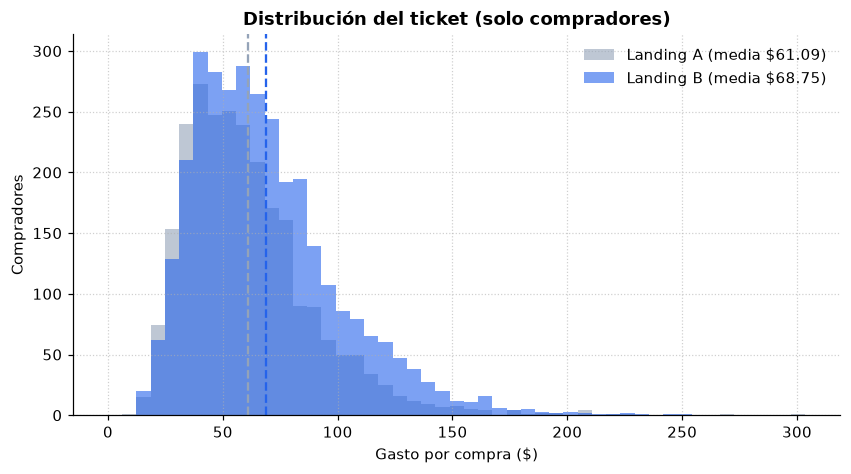

In [8]:
# Ticket = gasto de quienes compraron
ticket_A = df.loc[(df['landing'] == 'A') & (df['converted'] == 1), 'gasto'].to_numpy()
ticket_B = df.loc[(df['landing'] == 'B') & (df['converted'] == 1), 'gasto'].to_numpy()

resumen_ticket = pd.DataFrame({
    'A': pd.Series(ticket_A).describe(), 'B': pd.Series(ticket_B).describe()}).T
resumen_ticket['asimetria'] = [stats.skew(ticket_A), stats.skew(ticket_B)]
print(resumen_ticket)

fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.linspace(0, max(ticket_A.max(), ticket_B.max()), 50)
for g, datos in [('A', ticket_A), ('B', ticket_B)]:
    ax.hist(datos, bins=bins, alpha=0.6, color=COLORES[g], label=f'Landing {g} (media ${datos.mean():.2f})')
    ax.axvline(datos.mean(), color=COLORES[g], linestyle='--', linewidth=1.5)
ax.set_title('Distribución del ticket (solo compradores)', fontweight='bold')
ax.set_xlabel('Gasto por compra ($)')
ax.set_ylabel('Compradores')
ax.legend(frameon=False)
guardar(fig, 'ticket_distribution.png')
plt.show()

El ticket tiene sesgo a la derecha (asimetría de 1.67 en A y 1.20 en B) y varianzas distintas. Con más de 2,500 compradores por grupo, el teorema del límite central hace que la **t de Welch** sea válida para comparar medias sin suponer varianzas iguales. Como control de robustez se agrega la prueba de **Mann-Whitney**, que no asume normalidad.

### 3.2 Prueba de hipótesis del ticket

- H₀: el ticket promedio de los compradores de B es igual al de A.
- H₁: los tickets promedio son diferentes.
- α = 0.05

In [9]:
# Welch t-test (varianzas distintas) sobre el ticket de compradores
t_tk, p_tk = stats.ttest_ind(ticket_B, ticket_A, equal_var=False)
diff_tk = ticket_B.mean() - ticket_A.mean()
se_tk = np.sqrt(ticket_A.var(ddof=1) / len(ticket_A) + ticket_B.var(ddof=1) / len(ticket_B))
# grados de libertad de Welch-Satterthwaite
va, vb = ticket_A.var(ddof=1) / len(ticket_A), ticket_B.var(ddof=1) / len(ticket_B)
gl_tk = (va + vb) ** 2 / (va ** 2 / (len(ticket_A) - 1) + vb ** 2 / (len(ticket_B) - 1))
tcrit = stats.t.ppf(0.975, gl_tk)
ic_tk = (diff_tk - tcrit * se_tk, diff_tk + tcrit * se_tk)
# Tamaño del efecto (d de Cohen con desviación agrupada)
sd_pool = np.sqrt(((len(ticket_A) - 1) * ticket_A.var(ddof=1) + (len(ticket_B) - 1) * ticket_B.var(ddof=1))
                  / (len(ticket_A) + len(ticket_B) - 2))
d_tk = diff_tk / sd_pool
# Robustez: Mann-Whitney (no paramétrica)
u_tk, p_mw = stats.mannwhitneyu(ticket_B, ticket_A, alternative='two-sided')

print(f"Ticket A: ${ticket_A.mean():.2f} (n={len(ticket_A):,}) | Ticket B: ${ticket_B.mean():.2f} (n={len(ticket_B):,})")
print(f"Diferencia B - A: ${diff_tk:.2f} ({diff_tk / ticket_A.mean():.2%})  IC 95%: [${ic_tk[0]:.2f}, ${ic_tk[1]:.2f}]")
print(f"Welch: t = {t_tk:.3f}, gl = {gl_tk:.0f}, p = {p_tk:.3e}")
print(f"d de Cohen = {d_tk:.3f}")
print(f"Mann-Whitney: p = {p_mw:.3e}")

Ticket A: $61.09 (n=2,512) | Ticket B: $68.75 (n=3,194)
Diferencia B - A: $7.66 (12.54%)  IC 95%: [$6.08, $9.24]
Welch: t = 9.481, gl = 5598, p = 3.628e-21
d de Cohen = 0.250
Mann-Whitney: p = 1.044e-21


**Resultado:** el ticket sube de \$61.09 a \$68.75 (+\$7.66, +12.5%; IC 95%: \$6.08 a \$9.24). Welch da p = 3.6 × 10⁻²¹ y Mann-Whitney llega a la misma conclusión (p = 1.0 × 10⁻²¹). El d de Cohen es 0.25, un efecto pequeño en términos estadísticos pero relevante para el negocio. **Se rechaza H₀.**

### 3.3 ARPU (ingreso por visitante)

El ARPU combina las dos palancas (convertir más y vender más caro), y es la métrica más cercana al ingreso.

In [10]:
# ARPU: gasto promedio por visitante (incluye ceros de quienes no compraron)
gasto_A = df.loc[df['landing'] == 'A', 'gasto'].to_numpy()
gasto_B = df.loc[df['landing'] == 'B', 'gasto'].to_numpy()
t_arpu, p_arpu = stats.ttest_ind(gasto_B, gasto_A, equal_var=False)
diff_arpu = gasto_B.mean() - gasto_A.mean()
se_arpu = np.sqrt(gasto_A.var(ddof=1) / len(gasto_A) + gasto_B.var(ddof=1) / len(gasto_B))
ic_arpu = (diff_arpu - 1.96 * se_arpu, diff_arpu + 1.96 * se_arpu)
print(f"ARPU A: ${gasto_A.mean():.2f} | ARPU B: ${gasto_B.mean():.2f}")
print(f"Diferencia: ${diff_arpu:.2f} ({diff_arpu / gasto_A.mean():.2%})  IC 95% (normal): [${ic_arpu[0]:.2f}, ${ic_arpu[1]:.2f}]")
print(f"Welch: t = {t_arpu:.3f}, p = {p_arpu:.3e}")

ARPU A: $7.68 | ARPU B: $10.97
Diferencia: $3.29 (42.83%)  IC 95% (normal): [$2.79, $3.79]
Welch: t = 12.844, p = 1.115e-37


**Resultado:** el ARPU pasa de \$7.68 a \$10.97 por visitante (+\$3.29, +42.8%; IC 95%: \$2.79 a \$3.79; p = 1.1 × 10⁻³⁷).

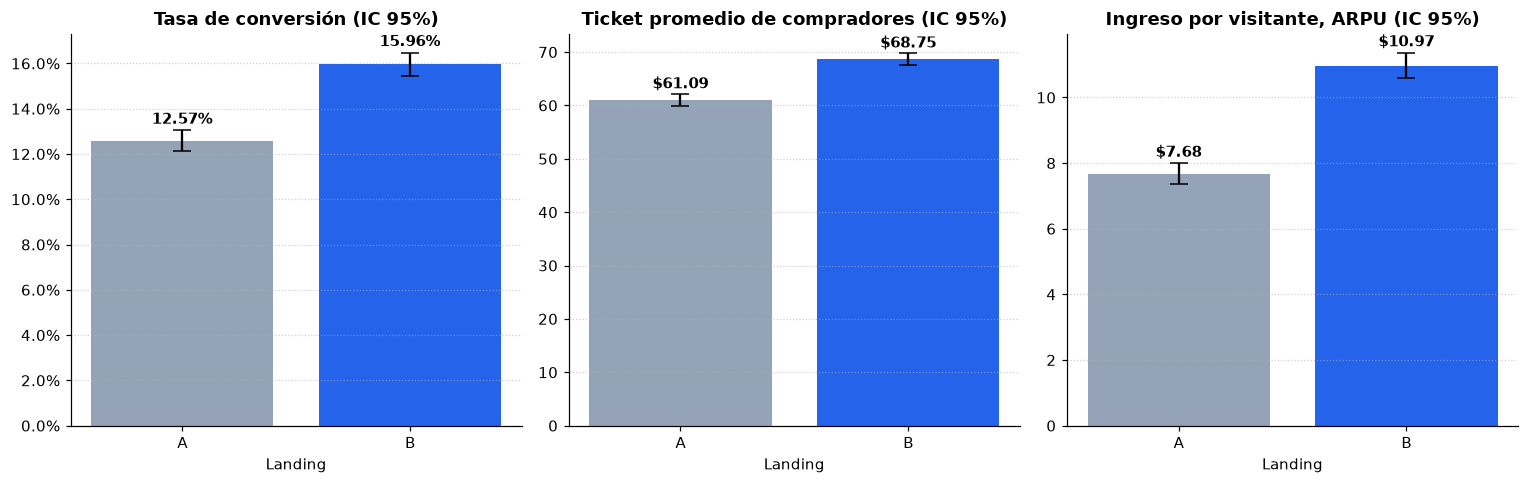

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
grupos = ['A', 'B']
# 1) Conversión
tasas = conv['tasa'].values
err = np.array([tasas - conv['ic_inf'].values, conv['ic_sup'].values - tasas])
axes[0].bar(grupos, tasas, yerr=err, capsize=6, color=[COLORES[g] for g in grupos])
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[0].set_title('Tasa de conversión (IC 95%)', fontweight='bold')
for i, t in enumerate(tasas):
    axes[0].text(i, t + err[1][i] + 0.003, f'{t:.2%}', ha='center', fontweight='bold')
# 2) Ticket
medias = [ticket_A.mean(), ticket_B.mean()]
errs = [1.96 * ticket_A.std(ddof=1) / np.sqrt(len(ticket_A)), 1.96 * ticket_B.std(ddof=1) / np.sqrt(len(ticket_B))]
axes[1].bar(grupos, medias, yerr=errs, capsize=6, color=[COLORES[g] for g in grupos])
axes[1].set_title('Ticket promedio de compradores (IC 95%)', fontweight='bold')
for i, m in enumerate(medias):
    axes[1].text(i, m + errs[i] + 1, f'${m:.2f}', ha='center', fontweight='bold')
# 3) ARPU
medias = [gasto_A.mean(), gasto_B.mean()]
errs = [1.96 * gasto_A.std(ddof=1) / np.sqrt(len(gasto_A)), 1.96 * gasto_B.std(ddof=1) / np.sqrt(len(gasto_B))]
axes[2].bar(grupos, medias, yerr=errs, capsize=6, color=[COLORES[g] for g in grupos])
axes[2].set_title('Ingreso por visitante, ARPU (IC 95%)', fontweight='bold')
for i, m in enumerate(medias):
    axes[2].text(i, m + errs[i] + 0.2, f'${m:.2f}', ha='center', fontweight='bold')
for ax in axes:
    ax.set_xlabel('Landing')
    ax.grid(axis='x', visible=False)
fig.tight_layout()
guardar(fig, 'ab_summary.png')
plt.show()

## 4. Estabilidad en el tiempo

Una ventaja que aparece solo los primeros días puede ser un **efecto novedad**. Se revisa la conversión día por día.

Días en que B convierte más que A: 27 de 28
Pendiente del lift diario: 0.053 pp/día (p = 0.137)


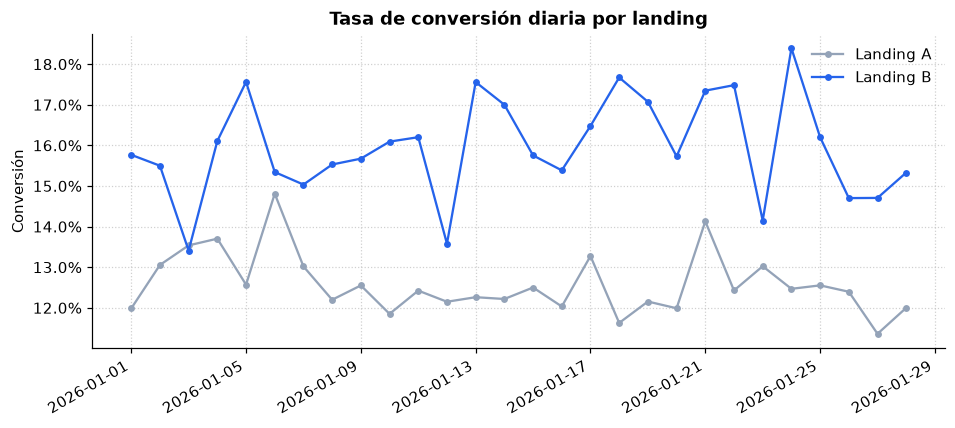

In [12]:
# Conversión diaria por landing: ¿la ventaja de B es estable o hay efecto novedad?
conv_diaria = df.groupby(['date', 'landing'], observed=True)['converted'].mean().unstack()
dias_B_gana = (conv_diaria['B'] > conv_diaria['A']).sum()
print(f"Días en que B convierte más que A: {dias_B_gana} de {len(conv_diaria)}")
# Tendencia del lift diario (pendiente de una regresión lineal simple)
lift_diario = conv_diaria['B'] - conv_diaria['A']
pend = stats.linregress(np.arange(len(lift_diario)), lift_diario.values)
print(f"Pendiente del lift diario: {pend.slope * 100:.3f} pp/día (p = {pend.pvalue:.3f})")

fig, ax = plt.subplots(figsize=(10, 4.2))
for g in ['A', 'B']:
    ax.plot(conv_diaria.index, conv_diaria[g], marker='o', ms=3.5, color=COLORES[g], label=f'Landing {g}')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title('Tasa de conversión diaria por landing', fontweight='bold')
ax.set_ylabel('Conversión')
ax.legend(frameon=False)
fig.autofmt_xdate()
guardar(fig, 'daily_conversion.png')
plt.show()

B supera a A en 27 de los 28 días, y la pendiente del lift diario no es significativa (p = 0.137): no hay señales de que la ventaja se esté desvaneciendo dentro del periodo observado.

## 5. Intervalos bootstrap del lift

Los intervalos anteriores usan aproximaciones normales. El **bootstrap** (10,000 remuestreos) no depende de esa suposición y permite obtener directamente el IC del **lift relativo** (un cociente, cuya distribución no es normal).

In [13]:
B_ITER = 10_000

# 1) Lift relativo de conversión: remuestreo de Bernoulli equivale a Binomial(n, p_obs)
boot_pA = rng.binomial(nA, pA, B_ITER) / nA
boot_pB = rng.binomial(nB, pB, B_ITER) / nB
boot_lift_conv = boot_pB / boot_pA - 1
boot_diff_conv = boot_pB - boot_pA

# 2) Lift relativo del ticket promedio (remuestreo de compradores)
def boot_medias(x, iters, rng, bloque=1000):
    out = np.empty(iters)
    for i in range(0, iters, bloque):
        k = min(bloque, iters - i)
        idx = rng.integers(0, len(x), size=(k, len(x)))
        out[i:i + k] = x[idx].mean(axis=1)
    return out

boot_tkA = boot_medias(ticket_A, B_ITER, rng)
boot_tkB = boot_medias(ticket_B, B_ITER, rng)
boot_lift_tk = boot_tkB / boot_tkA - 1
boot_diff_tk = boot_tkB - boot_tkA

# 3) Diferencia de ARPU (remuestreo de visitantes, por bloques para ahorrar memoria)
boot_arpuA = boot_medias(gasto_A, B_ITER, rng, bloque=250)
boot_arpuB = boot_medias(gasto_B, B_ITER, rng, bloque=250)
boot_diff_arpu = boot_arpuB - boot_arpuA

def ic(x):
    return np.percentile(x, [2.5, 97.5])

res_boot = pd.DataFrame({
    'métrica': ['Lift relativo conversión', 'Diferencia conversión (pp)',
                'Lift relativo ticket', 'Diferencia ticket ($)', 'Diferencia ARPU ($)'],
    'observado': [pB / pA - 1, (pB - pA) * 100, ticket_B.mean() / ticket_A.mean() - 1, diff_tk, diff_arpu],
    'ic_2.5%': [ic(boot_lift_conv)[0], ic(boot_diff_conv)[0] * 100, ic(boot_lift_tk)[0], ic(boot_diff_tk)[0], ic(boot_diff_arpu)[0]],
    'ic_97.5%': [ic(boot_lift_conv)[1], ic(boot_diff_conv)[1] * 100, ic(boot_lift_tk)[1], ic(boot_diff_tk)[1], ic(boot_diff_arpu)[1]],
    'P(B <= A)': [(boot_lift_conv <= 0).mean(), (boot_diff_conv <= 0).mean(), (boot_lift_tk <= 0).mean(),
                  (boot_diff_tk <= 0).mean(), (boot_diff_arpu <= 0).mean()],
})
res_boot

,métrica,observado,ic_2.5%,ic_97.5%,P(B <= A)
0,Lift relativo conversión,0.2692,0.2095,0.3323,0.0000
1,Diferencia conversión (pp),3.3843,2.6997,4.0740,0.0000
2,Lift relativo ticket,0.1254,0.0979,0.1534,0.0000
3,Diferencia ticket ($),7.6588,6.0694,9.2391,0.0000
4,Diferencia ARPU ($),3.2894,2.7879,3.7966,0.0000


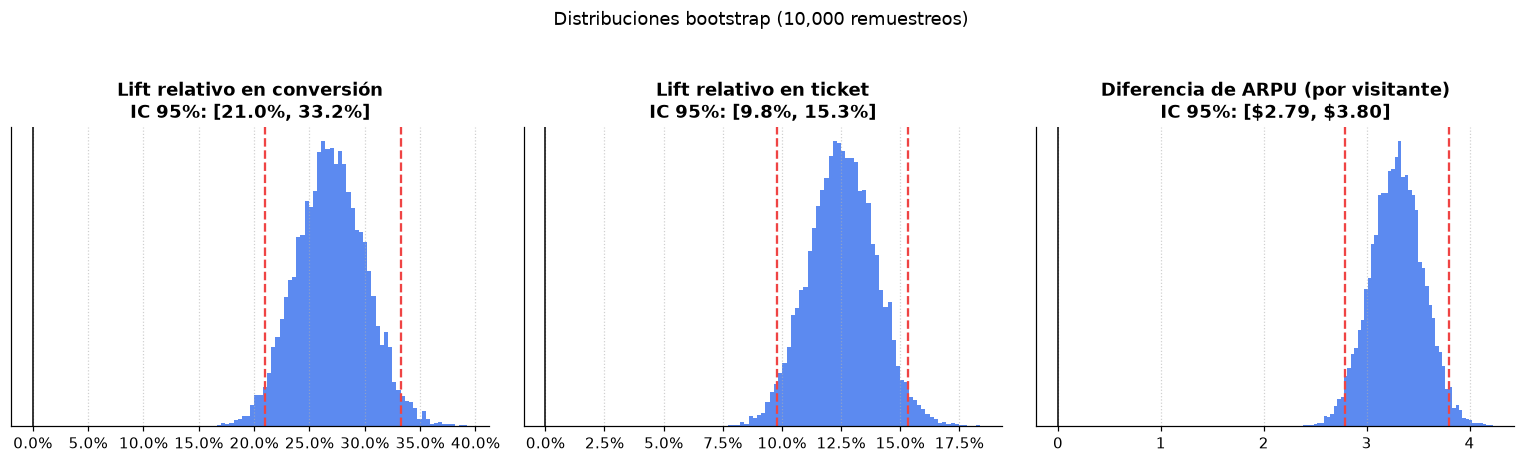

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, datos, titulo, fmt in [
        (axes[0], boot_lift_conv, 'Lift relativo en conversión', 'pct'),
        (axes[1], boot_lift_tk, 'Lift relativo en ticket', 'pct'),
        (axes[2], boot_diff_arpu, 'Diferencia de ARPU (por visitante)', 'usd')]:
    lo, hi = ic(datos)
    ax.hist(datos, bins=60, color=COLORES['B'], alpha=0.75)
    ax.axvline(lo, color='#ef4444', linestyle='--')
    ax.axvline(hi, color='#ef4444', linestyle='--')
    ax.axvline(0, color='black', linewidth=1)
    if fmt == 'pct':
        ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
        ax.set_title(f'{titulo}\nIC 95%: [{lo:.1%}, {hi:.1%}]', fontweight='bold')
    else:
        ax.set_title(rf'{titulo}' + '\n' + rf'IC 95%: [\${lo:.2f}, \${hi:.2f}]', fontweight='bold')
    ax.set_yticks([])
fig.suptitle(f'Distribuciones bootstrap ({B_ITER:,} remuestreos)', y=1.04)
fig.tight_layout()
guardar(fig, 'bootstrap_lifts.png')
plt.show()

**Resultado:** el lift relativo en conversión es de +26.9% (IC 95% bootstrap: +21.0% a +33.2%) y el del ticket es de +12.5% (+9.8% a +15.3%). La diferencia de ARPU es de \$3.29 (\$2.79 a \$3.80). En ninguno de los 10,000 remuestreos B quedó por debajo de A. Los intervalos bootstrap coinciden con los analíticos, lo que confirma que las aproximaciones normales eran adecuadas.

## 6. Análisis de potencia y efecto mínimo detectable (MDE)

Un resultado significativo solo es confiable si el experimento tenía tamaño suficiente. Aquí se responde:

- ¿Qué efecto mínimo podía detectar este experimento con 80% de potencia?
- ¿Cuántos usuarios por grupo se necesitan para detectar distintos lifts con la conversión base de A?
- ¿Qué potencia tuvo el experimento para el efecto observado?

In [15]:
analisis_potencia = NormalIndPower()
POTENCIA = 0.80
n_grupo = min(nA, nB)

# a) Efecto mínimo detectable (MDE) con el tamaño real de cada grupo
h_mde = analisis_potencia.solve_power(effect_size=None, nobs1=nA, ratio=nB / nA, alpha=ALPHA, power=POTENCIA)
# Convertir h de Cohen (h = 2 asin(sqrt(p2)) - 2 asin(sqrt(p1))) a una tasa
p_mde = np.sin(np.arcsin(np.sqrt(pA)) + h_mde / 2) ** 2
print(f"Línea base (A): {pA:.2%} | n por grupo ≈ {n_grupo:,}")
print(f"MDE con 80% de potencia y alfa 5%: {(p_mde - pA) * 100:.2f} pp absolutos ({p_mde / pA - 1:.1%} relativo), "
      f"es decir, detectar {pA:.2%} -> {p_mde:.2%}")

# b) Potencia alcanzada para el efecto observado
h_obs = proportion_effectsize(pB, pA)
potencia_obs = analisis_potencia.power(effect_size=h_obs, nobs1=nA, ratio=nB / nA, alpha=ALPHA)
print(f"h de Cohen observado: {h_obs:.4f} | potencia alcanzada: {potencia_obs:.4f}")

# c) Tamaño de muestra requerido por grupo para distintos lifts relativos
filas = []
for lift in [0.05, 0.10, 0.15, 0.20, pB / pA - 1]:
    h = proportion_effectsize(pA * (1 + lift), pA)
    n_req = analisis_potencia.solve_power(effect_size=h, alpha=ALPHA, power=POTENCIA, ratio=1)
    filas.append({'lift_relativo': lift, 'tasa_B_objetivo': pA * (1 + lift), 'n_por_grupo': int(np.ceil(n_req))})
tabla_n = pd.DataFrame(filas)
tabla_n['¿alcanzado?'] = tabla_n['n_por_grupo'] <= n_grupo
print()
print(tabla_n.to_string(index=False, formatters={'lift_relativo': '{:.1%}'.format, 'tasa_B_objetivo': '{:.2%}'.format}))

# d) Potencia para el ticket (d de Cohen observado)
# (con n grandes la aproximación normal es adecuada)
potencia_tk = analisis_potencia.power(effect_size=d_tk, nobs1=len(ticket_A), ratio=len(ticket_B) / len(ticket_A), alpha=ALPHA)
d_mde_tk = analisis_potencia.solve_power(effect_size=None, nobs1=len(ticket_A), ratio=len(ticket_B) / len(ticket_A), alpha=ALPHA, power=POTENCIA)
print(f"\nTicket: potencia alcanzada con d = {d_tk:.3f}: {potencia_tk:.4f} | MDE (d) = {d_mde_tk:.3f} "
      f"≈ ${d_mde_tk * sd_pool:.2f}")

Línea base (A): 12.57% | n por grupo ≈ 19,982
MDE con 80% de potencia y alfa 5%: 0.94 pp absolutos (7.5% relativo), es decir, detectar 12.57% -> 13.51%
h de Cohen observado: 0.0969 | potencia alcanzada: 1.0000

lift_relativo tasa_B_objetivo  n_por_grupo  ¿alcanzado?
         5.0%          13.20%        44594        False
        10.0%          13.83%        11375         True
        15.0%          14.46%         5154         True
        20.0%          15.09%         2954         True
        26.9%          15.96%         1671         True

Ticket: potencia alcanzada con d = 0.250: 1.0000 | MDE (d) = 0.075 ≈ $2.29


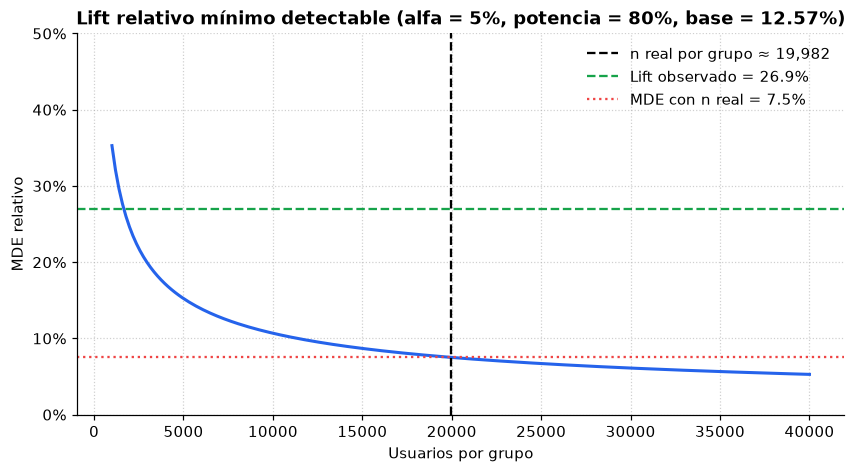

In [16]:
# Curva: lift relativo mínimo detectable vs. tamaño de muestra por grupo
ns = np.linspace(1_000, 40_000, 200)
mde_rel = []
for n in ns:
    h = analisis_potencia.solve_power(effect_size=None, nobs1=n, ratio=1, alpha=ALPHA, power=POTENCIA)
    mde_rel.append(np.sin(np.arcsin(np.sqrt(pA)) + h / 2) ** 2 / pA - 1)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(ns, mde_rel, color=COLORES['B'], linewidth=2)
ax.axvline(n_grupo, color='black', linestyle='--', label=f'n real por grupo ≈ {n_grupo:,}')
ax.axhline(pB / pA - 1, color='#16a34a', linestyle='--', label=f'Lift observado = {pB / pA - 1:.1%}')
ax.axhline(p_mde / pA - 1, color='#ef4444', linestyle=':', label=f'MDE con n real = {p_mde / pA - 1:.1%}')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0, 0.5)
ax.set_title(f'Lift relativo mínimo detectable (alfa = 5%, potencia = 80%, base = {pA:.2%})', fontweight='bold')
ax.set_xlabel('Usuarios por grupo')
ax.set_ylabel('MDE relativo')
ax.legend(frameon=False)
guardar(fig, 'power_mde_curve.png')
plt.show()

**Resultado:**

- Con ~20,000 usuarios por grupo y una conversión base de 12.57%, el experimento podía detectar un aumento de **0.94 pp (7.5% relativo)** con 80% de potencia.
- El lift observado (+26.9%) es más de tres veces ese MDE. Para detectarlo habrían bastado unos 1,671 usuarios por grupo, y la potencia alcanzada es prácticamente 100%.
- En cambio, un lift de 5% habría requerido unos 44,600 usuarios por grupo, más del doble de los que hubo. **El experimento estaba bien dimensionado para efectos de 7.5% en adelante, pero no para efectos muy pequeños.**
- Para el ticket, la potencia también es prácticamente total: el MDE es d ≈ 0.075 (≈ \$2.29), muy por debajo de la diferencia observada de \$7.66.

Nota: en un experimento real, el tamaño de muestra se fija **antes** de lanzarlo; calcular la potencia "observada" después solo sirve como verificación. Lo que aporta más al planear el siguiente test es la tabla de tamaños de muestra.

## 7. Análisis por segmento

### 7.1 Asociación entre segmento y conversión (análisis original)

**Fuente de tráfico**
- H₀: la conversión es independiente del canal. H₁: la conversión depende del canal. α = 0.05

**Tipo de usuario**
- H₀: la conversión es independiente del tipo de usuario. H₁: la conversión depende del tipo de usuario. α = 0.05

In [17]:
# Análisis original: asociación entre segmento y conversión (todas las landings)
def cramers_v(tabla):
    chi2 = stats.chi2_contingency(tabla, correction=False)[0]
    n = tabla.to_numpy().sum()
    return np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))

for col in ['traffic_source', 'user_type']:
    tabla = pd.crosstab(df[col], df['converted'])
    chi2, p, dof, _ = stats.chi2_contingency(tabla, correction=False)
    tasas = df.groupby(col, observed=True)['converted'].agg(['count', 'sum', 'mean'])
    print(f"--- {col} ---")
    print(tasas.to_string(formatters={'mean': '{:.2%}'.format}))
    print(f"chi2 = {chi2:.3f}, gl = {dof}, p = {p:.4f}, V de Cramér = {cramers_v(tabla):.3f}\n")

--- traffic_source ---
                count   sum   mean
traffic_source                    
Ads             11935  1759 14.74%
Email            6123   918 14.99%
Organic         17987  2480 13.79%
Referral         3955   549 13.88%
chi2 = 8.662, gl = 3, p = 0.0341, V de Cramér = 0.015

--- user_type ---
            count   sum   mean
user_type                     
Nuevo       26033  3738 14.36%
Recurrente  13967  1968 14.09%
chi2 = 0.535, gl = 1, p = 0.4644, V de Cramér = 0.004



- **Canal:** hay una asociación significativa pero muy débil (p = 0.034; V de Cramér = 0.015). Email (14.99%) y Ads (14.74%) convierten un poco más que Referral (13.88%) y Organic (13.79%). Organic aporta el mayor volumen de compras (2,480). El canal no se asignó al azar, así que esta diferencia no implica causalidad.
- **Tipo de usuario:** no hay evidencia de diferencia entre nuevos (14.36%) y recurrentes (14.09%), p = 0.464. Un valor p alto no demuestra que sean iguales; solo indica que estos datos no muestran una diferencia.

### 7.2 Lift de B dentro de cada segmento

La pregunta más útil para el negocio es si **B gana en todos los segmentos**. Se hacen 13 comparaciones (4 canales, 2 tipos de usuario, 2 dispositivos y 5 regiones). Con tantas pruebas, la probabilidad de encontrar al menos un "falso positivo" crece, así que los valores p se ajustan con **Holm** (y con Bonferroni como referencia, más conservador).

In [18]:
# Lift de B vs A dentro de cada segmento, con corrección por comparaciones múltiples
filas = []
for col in ['traffic_source', 'user_type', 'dispositivo', 'region']:
    for nivel, sub in df.groupby(col, observed=True):
        a = sub[sub['landing'] == 'A']['converted']
        b = sub[sub['landing'] == 'B']['converted']
        z, p = proportions_ztest([b.sum(), a.sum()], [len(b), len(a)])
        lo, hi = confint_proportions_2indep(b.sum(), len(b), a.sum(), len(a), method='newcomb', compare='diff')
        filas.append({'variable': col, 'segmento': nivel, 'n_A': len(a), 'n_B': len(b),
                      'conv_A': a.mean(), 'conv_B': b.mean(), 'diff_pp': (b.mean() - a.mean()) * 100,
                      'ic_inf_pp': lo * 100, 'ic_sup_pp': hi * 100,
                      'lift_rel': b.mean() / a.mean() - 1, 'p_valor': p})
seg = pd.DataFrame(filas)
seg['p_bonferroni'] = multipletests(seg['p_valor'], alpha=ALPHA, method='bonferroni')[1]
seg['p_holm'] = multipletests(seg['p_valor'], alpha=ALPHA, method='holm')[1]
seg['signif_holm'] = seg['p_holm'] < ALPHA
print(f"Comparaciones: {len(seg)} | significativas tras Holm: {seg['signif_holm'].sum()} | "
      f"segmentos donde B > A: {(seg['diff_pp'] > 0).sum()}")
seg.style.format({'conv_A': '{:.2%}', 'conv_B': '{:.2%}', 'diff_pp': '{:.2f}', 'ic_inf_pp': '{:.2f}',
                  'ic_sup_pp': '{:.2f}', 'lift_rel': '{:.1%}', 'p_valor': '{:.2e}',
                  'p_bonferroni': '{:.2e}', 'p_holm': '{:.2e}'}).hide(axis='index')

Comparaciones: 13 | significativas tras Holm: 13 | segmentos donde B > A: 13


variable,segmento,n_A,n_B,conv_A,conv_B,diff_pp,ic_inf_pp,ic_sup_pp,lift_rel,p_valor,p_bonferroni,p_holm,signif_holm
traffic_source,Ads,5981,5954,12.99%,16.49%,3.50,2.23,4.77,27.0%,6.80e-08,8.84e-07,6.12e-07,True
traffic_source,Email,3087,3036,13.51%,16.50%,2.99,1.21,4.78,22.2%,1.04e-03,1.35e-02,1.04e-03,True
traffic_source,Organic,8992,8995,12.11%,15.46%,3.35,2.35,4.36,27.7%,6.92e-11,9.00e-10,7.62e-10,True
traffic_source,Referral,1922,2033,11.91%,15.74%,3.83,1.67,5.97,32.1%,5.05e-04,6.57e-03,1.01e-03,True
user_type,Nuevo,12992,13041,12.73%,15.98%,3.25,2.40,4.10,25.5%,7.69e-14,9.99e-13,9.23e-13,True
user_type,Recurrente,6990,6977,12.27%,15.91%,3.63,2.48,4.79,29.6%,6.69e-10,8.70e-09,6.69e-09,True
dispositivo,Desktop,7571,7600,14.71%,17.49%,2.77,1.60,3.94,18.8%,3.39e-06,4.40e-05,2.03e-05,True
dispositivo,Mobile,12411,12418,11.26%,15.02%,3.75,2.92,4.59,33.3%,2.04e-18,2.66e-17,2.66e-17,True
region,Centro,4822,4791,13.23%,15.82%,2.59,1.18,4.00,19.6%,3.13e-04,4.07e-03,9.39e-04,True
region,Norte,5553,5613,13.16%,16.07%,2.91,1.60,4.22,22.1%,1.39e-05,1.81e-04,6.97e-05,True


**Resultado:** B supera a A en los 13 segmentos y las 13 diferencias siguen siendo significativas después de ajustar por Holm (la más débil es Email, p ajustada = 0.001; con Bonferroni = 0.013). Los lifts van de +2.59 pp (Centro) a +4.46 pp (Occidente).

### 7.3 ¿Paradoja de Simpson?

La paradoja de Simpson ocurre cuando el efecto agregado cambia de dirección (o desaparece) al separar por segmentos, normalmente porque los grupos tienen una mezcla distinta de segmentos. Se compara la razón de momios cruda con la ajustada por Mantel-Haenszel en cada variable y se prueba si el efecto es homogéneo entre segmentos (Breslow-Day).

In [19]:
# ¿Paradoja de Simpson? Compara el efecto agregado con el efecto ajustado por segmento (Mantel-Haenszel)
or_crudo = (xB / (nB - xB)) / (xA / (nA - xA))
print(f"Razón de momios cruda (B vs A): {or_crudo:.3f}")
for col in ['traffic_source', 'user_type', 'dispositivo', 'region']:
    tablas = []
    for _, sub in df.groupby(col, observed=True):
        t = pd.crosstab(sub['landing'], sub['converted']).loc[['B', 'A'], [1, 0]].to_numpy()
        tablas.append(t)
    st = StratifiedTable(tablas)
    signos = seg.loc[seg['variable'] == col, 'diff_pp'] > 0
    print(f"{col:15s} OR Mantel-Haenszel = {st.oddsratio_pooled:.3f} | "
          f"homogeneidad (Breslow-Day) p = {st.test_equal_odds().pvalue:.3f} | "
          f"B > A en {signos.sum()}/{len(signos)} segmentos")

Razón de momios cruda (B vs A): 1.320
traffic_source  OR Mantel-Haenszel = 1.321 | homogeneidad (Breslow-Day) p = 0.897 | B > A en 4/4 segmentos
user_type       OR Mantel-Haenszel = 1.320 | homogeneidad (Breslow-Day) p = 0.547 | B > A en 2/2 segmentos
dispositivo     OR Mantel-Haenszel = 1.321 | homogeneidad (Breslow-Day) p = 0.032 | B > A en 2/2 segmentos


region          OR Mantel-Haenszel = 1.321 | homogeneidad (Breslow-Day) p = 0.330 | B > A en 5/5 segmentos


**Resultado:** no hay paradoja de Simpson. La razón de momios ajustada por cada variable (1.320 a 1.321) es prácticamente igual a la cruda (1.320), y B gana en todos los segmentos. Esto era esperable porque la mezcla de segmentos está balanceada entre A y B (sección 1.1).

La prueba de homogeneidad sugiere que el efecto podría ser algo mayor en **Mobile** (+3.75 pp, lift de +33.3%) que en **Desktop** (+2.77 pp, +18.8%), con p = 0.032. Como son 4 pruebas de homogeneidad, al corregir (p × 4 ≈ 0.13) la diferencia deja de ser concluyente. Lo tomo como hipótesis para un siguiente experimento, no como hallazgo.

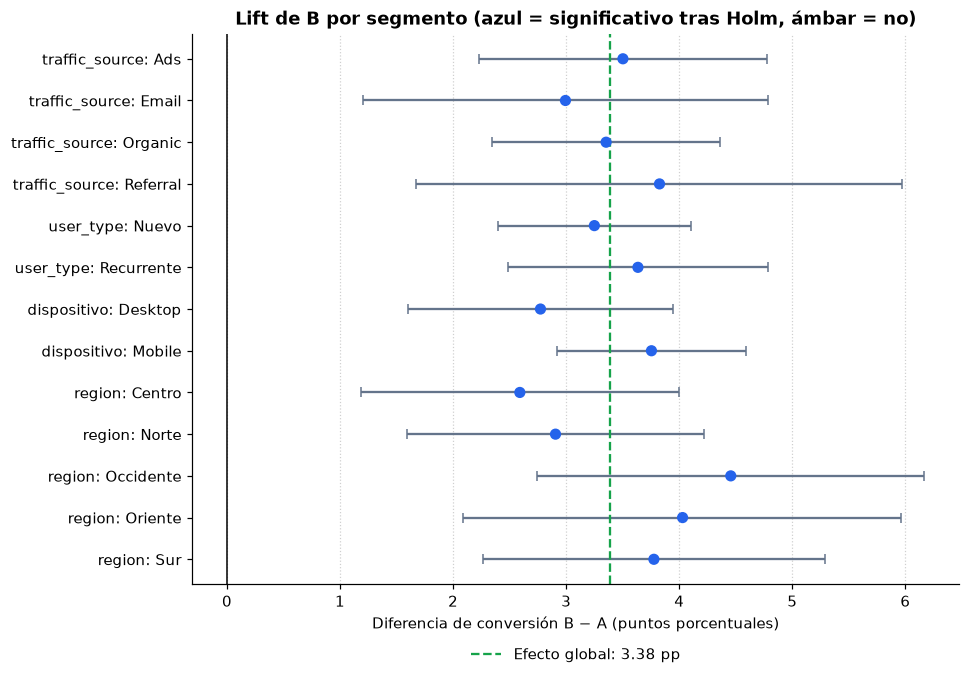

In [20]:
# Forest plot: diferencia de conversión B - A por segmento (IC 95% sin ajustar)
seg_plot = seg.iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 6.5))
y = np.arange(len(seg_plot))
colores = [COLORES['B'] if s else '#f59e0b' for s in seg_plot['signif_holm']]
ax.errorbar(seg_plot['diff_pp'], y,
            xerr=[seg_plot['diff_pp'] - seg_plot['ic_inf_pp'], seg_plot['ic_sup_pp'] - seg_plot['diff_pp']],
            fmt='none', ecolor='#64748b', capsize=3)
ax.scatter(seg_plot['diff_pp'], y, color=colores, zorder=3, s=40)
ax.axvline(0, color='black', linewidth=1)
ax.axvline((pB - pA) * 100, color='#16a34a', linestyle='--', label=f'Efecto global: {(pB - pA) * 100:.2f} pp')
ax.set_yticks(y)
ax.set_yticklabels([f"{v}: {s}" for v, s in zip(seg_plot['variable'], seg_plot['segmento'])])
ax.set_xlabel('Diferencia de conversión B − A (puntos porcentuales)')
ax.set_title('Lift de B por segmento (azul = significativo tras Holm, ámbar = no)', fontweight='bold')
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.09))
ax.grid(axis='y', visible=False)
guardar(fig, 'segment_forest_plot.png')
plt.show()

## 8. Impacto de negocio estimado

Se proyecta el resultado a cada **10,000 visitantes**, usando las distribuciones bootstrap para el intervalo de confianza. El ingreso adicional se descompone en la parte que viene de convertir más y la que viene del ticket más alto.

In [21]:
# Impacto de negocio proyectado por cada 10,000 visitantes
VISITANTES = 10_000
impacto = pd.DataFrame({
    'métrica': ['Compras adicionales', 'Ingreso adicional ($)'],
    'estimado': [(pB - pA) * VISITANTES, diff_arpu * VISITANTES],
    'ic_2.5%': [ic(boot_diff_conv)[0] * VISITANTES, ic(boot_diff_arpu)[0] * VISITANTES],
    'ic_97.5%': [ic(boot_diff_conv)[1] * VISITANTES, ic(boot_diff_arpu)[1] * VISITANTES],
})
print(f"Ingreso con A por 10k visitantes: ${gasto_A.mean() * VISITANTES:,.0f} | con B: ${gasto_B.mean() * VISITANTES:,.0f}")

# Descomposición del ingreso adicional: cuánto viene de convertir más y cuánto del ticket más alto
efecto_conv = (pB - pA) * ticket_A.mean() * VISITANTES
efecto_ticket = pB * (ticket_B.mean() - ticket_A.mean()) * VISITANTES
print(f"Por más conversión: ${efecto_conv:,.0f} ({efecto_conv / (diff_arpu * VISITANTES):.0%}) | "
      f"por ticket más alto: ${efecto_ticket:,.0f} ({efecto_ticket / (diff_arpu * VISITANTES):.0%})")
impacto

Ingreso con A por 10k visitantes: $76,794 | con B: $109,688
Por más conversión: $20,674 (63%) | por ticket más alto: $12,220 (37%)


,métrica,estimado,ic_2.5%,ic_97.5%
0,Compras adicionales,338.4326,269.9687,407.4047
1,Ingreso adicional ($),"32,893.7717","27,879.1437","37,965.5736"


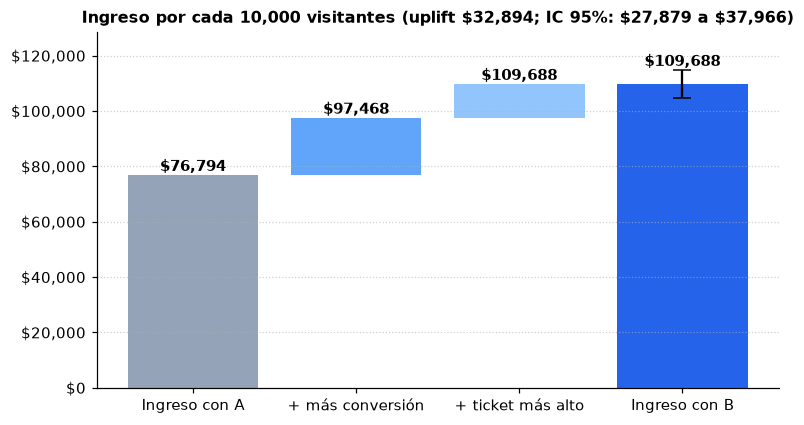

In [22]:
fig, ax = plt.subplots(figsize=(8, 4.2))
base = gasto_A.mean() * VISITANTES
lo, hi = ic(boot_diff_arpu) * VISITANTES
ax.bar(['Ingreso con A', '+ más conversión', '+ ticket más alto', 'Ingreso con B'],
       [base, efecto_conv, efecto_ticket, gasto_B.mean() * VISITANTES],
       bottom=[0, base, base + efecto_conv, 0],
       color=[COLORES['A'], '#60a5fa', '#93c5fd', COLORES['B']])
ax.errorbar(3, gasto_B.mean() * VISITANTES, yerr=[[diff_arpu * VISITANTES - lo], [hi - diff_arpu * VISITANTES]],
            fmt='none', ecolor='black', capsize=6)
for i, v in enumerate([base, base + efecto_conv, base + efecto_conv + efecto_ticket, gasto_B.mean() * VISITANTES]):
    extra = (hi - diff_arpu * VISITANTES) if i == 3 else 0
    ax.text(i, v + extra + 1500, f'${v:,.0f}', ha='center', fontweight='bold')
ax.set_title(rf'Ingreso por cada 10,000 visitantes (uplift \${diff_arpu * VISITANTES:,.0f}; IC 95%: \${lo:,.0f} a \${hi:,.0f})',
             fontweight='bold', fontsize=10.5)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.0f}'))
ax.set_ylim(0, (gasto_B.mean() * VISITANTES + hi - diff_arpu * VISITANTES) * 1.12)
ax.grid(axis='x', visible=False)
guardar(fig, 'business_impact.png')
plt.show()

**Resultado:** por cada 10,000 visitantes, B generaría unas **338 compras adicionales** (IC 95%: 270 a 407) y **\$32,894 de ingreso adicional** (IC 95%: \$27,879 a \$37,966), al pasar de \$76,794 a \$109,688. Alrededor del 63% del aumento viene de la mayor conversión y el 37% del ticket más alto.

Es ingreso bruto: no descuenta costos de producto, devoluciones ni el costo de implementar B.

## 9. Recomendación y limitaciones

### Recomendación

**Lanzar la Landing B al 100% del tráfico.**

- El experimento es válido: sin SRM, sin duplicados ni nulos, y con segmentos balanceados entre A y B.
- B mejora las tres métricas: conversión +26.9% (IC bootstrap +21.0% a +33.2%), ticket +12.5% (+9.8% a +15.3%) y ARPU +42.8%.
- El efecto es consistente: B gana en los 13 segmentos (todos significativos tras Holm) y en 27 de los 28 días.
- El experimento tenía potencia de sobra: el efecto observado es más de tres veces el mínimo detectable.
- Impacto estimado: unos \$32,900 adicionales por cada 10,000 visitantes (IC 95%: \$27,900 a \$38,000).

**Siguientes pasos**

1. Monitorear la conversión y el ARPU después del lanzamiento, con un pequeño grupo de control (por ejemplo, 5% del tráfico con A) durante algunas semanas, para confirmar que el efecto se mantiene.
2. Explorar si B funciona aún mejor en Mobile con un experimento diseñado para eso, con su tamaño de muestra calculado de antemano.
3. Para futuros tests con efectos esperados pequeños (≈5%), planear unos 45,000 usuarios por grupo.

### Limitaciones

- **Ventana de 28 días:** no permite ver efectos de largo plazo, estacionalidad ni recompras.
- **Ingreso bruto:** sin datos de margen, devoluciones ni costos.
- **Moneda no especificada** en el dataset.
- **El canal y el tipo de usuario no son aleatorios:** las diferencias entre canales son descriptivas, no causales. Solo la comparación A vs B es causal.
- **Los datos parecen sintéticos:** no hay ningún nulo ni inconsistencia, el tráfico diario es muy estable y el lift (+27%) es mayor de lo que suele verse en pruebas reales de landing pages. Los métodos se aplican igual, pero las magnitudes no deben tomarse como referencia de la industria.